# VOC12 dataset segmentation*

JPEG images: [link](https://drive.google.com/file/d/1MTgdBUwwBljzHIGz3bIqdLfu4qPx-PuP/view)

Ground truth labels: [link](https://drive.google.com/file/d/1lR-Ihrg7yE0YVS9PxZTW-_XT6C8rZEnc/view)

Propose a simple method for object segmentation. Pick 1-2 images from the provided dataset. You may use one or multiple segmentation methods such as:

- grabcut
- superpixel segmentation
- floodfill
- thresholding
- and so on ...

Use provided ground truth label to compute Dice Score with your prediction (you may choose only 1 specific object for segmentation in case of multiple objects presented in the image)

This part of segmentation using standard methods is optional for VOC12


In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import os

In [ ]:
image_dir = 'images/voc-data'
label_dir = 'images/voc-labels'

image_files = list(map(lambda f: os.path.join(image_dir, f), os.listdir(image_dir)))
label_files = list(map(lambda f: os.path.join(label_dir, f), os.listdir(label_dir)))

file1, file1_label = image_files[0], label_files[0]
file2, file2_label = image_files[1], label_files[1]

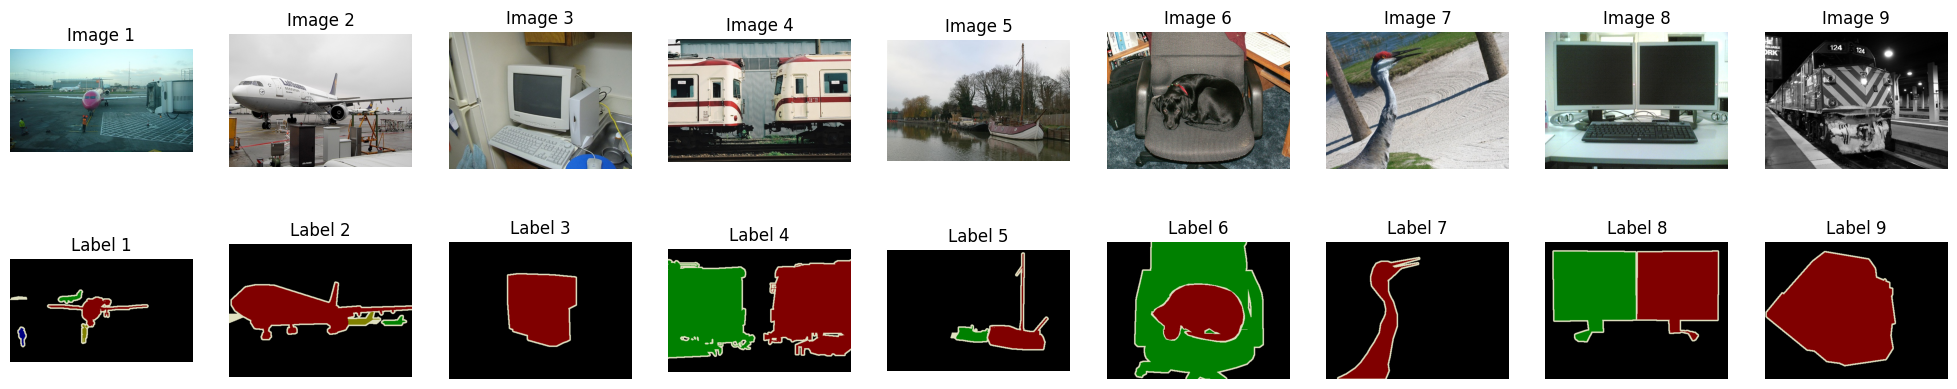

In [181]:
# Plot 9 the images with labels under the same figure
fig, axs = plt.subplots(2, 9, figsize=(25, 5))
for i in range(9):
    img = cv.imread(image_files[i])
    axs[0, i].imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    axs[0, i].axis('off')
    axs[0, i].set_title('Image {}'.format(i + 1))

    label = cv.imread(label_files[i])
    axs[1, i].imshow(cv.cvtColor(label, cv.COLOR_BGR2RGB))
    axs[1, i].axis('off')
    axs[1, i].set_title('Label {}'.format(i + 1))

plt.show()

## Superpixel segmentation

Number of superpixels: 70


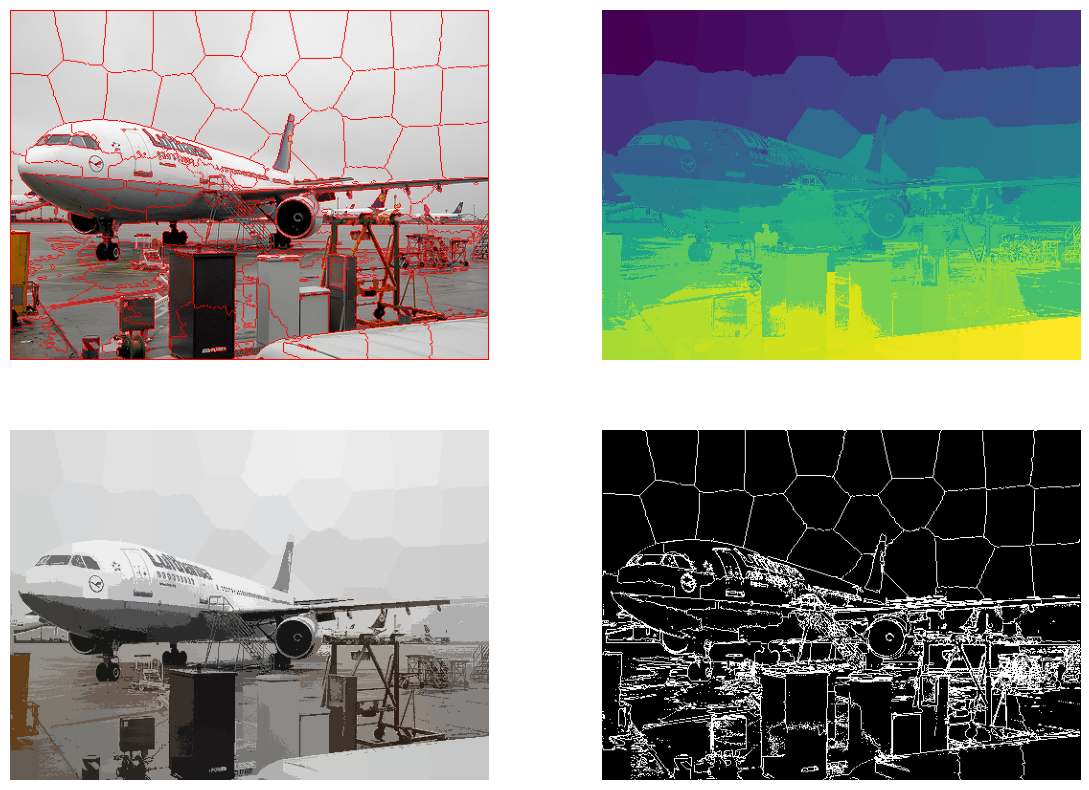

In [177]:
# read image
img = cv.imread(file2)
lab = cv.cvtColor(img, cv.COLOR_BGR2LAB)

# set up parameters
region_size = 50
ruler = 20.0

# apply superpixel segmentation
slic = cv.ximgproc.createSuperpixelSLIC(
    lab, cv.ximgproc.SLIC, region_size, ruler
)

slic.iterate(10)

# retrieve the segmentation result
labels = slic.getLabels()
contour_mask = slic.getLabelContourMask(False)
num_superpixels = slic.getNumberOfSuperpixels()
print(f'Number of superpixels: {num_superpixels}')

for label in np.unique(labels):
    mask = np.argwhere(label == labels)
    x, y = mask[:, 0], mask[:, 1]
    avg_color = np.mean(lab[x, y, :], axis=0)
    lab[x, y, :] = avg_color

superpixel_img = cv.cvtColor(lab, cv.COLOR_LAB2BGR)

# Apply watershed segmentation
markers = slic.getLabels()
markers = markers + 1
markers[contour_mask == 255] = 0
markers = cv.watershed(img, markers)

result = img.copy()
result[markers == -1] = [0, 0, 255]

# Visualize the superpixel segmentation
plt.subplots(2, 2, figsize=(14, 10))
plt.subplot(221)
plt.imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB))
plt.axis('off')
plt.subplot(222)
plt.imshow(labels)
plt.axis('off')
plt.subplot(223)
plt.imshow(cv.cvtColor(superpixel_img, cv.COLOR_BGR2RGB))
plt.axis('off')
plt.subplot(224)
plt.imshow(cv.cvtColor(contour_mask, cv.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

Number of superpixels: 165


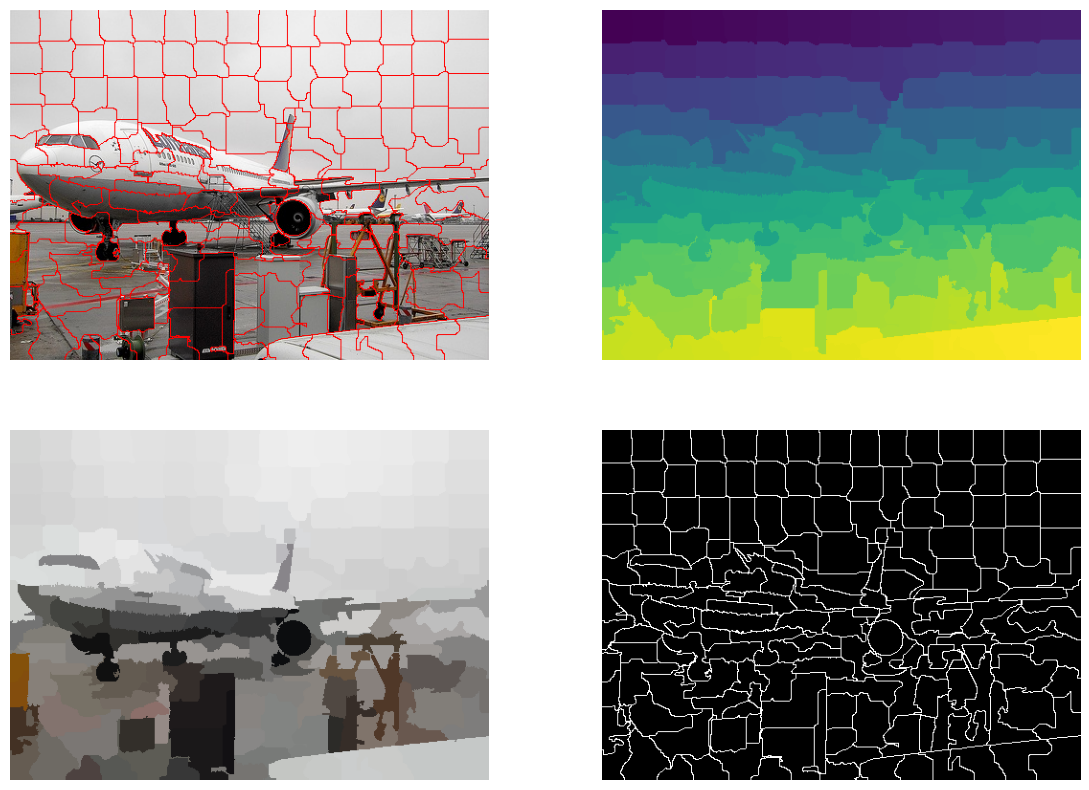

In [180]:
# read image
img = cv.imread(file2)
lab = cv.cvtColor(img, cv.COLOR_BGR2Lab)

# set up parameters
height, width, channels = lab.shape
num_superpixels = 200
num_levels = 4
prior = 2
num_histogram_bins = 5
double_step = False

# apply superpixel segmentation
seeds = cv.ximgproc.createSuperpixelSEEDS(
    width, height, channels, num_superpixels, num_levels, prior, num_histogram_bins, double_step
)

seeds.iterate(lab, 6)

# retrieve the segmentation result
labels = seeds.getLabels()
contour_mask = seeds.getLabelContourMask(False)
num_superpixels = seeds.getNumberOfSuperpixels()
print(f'Number of superpixels: {num_superpixels}')

for label in np.unique(labels):
    mask = np.argwhere(label == labels)
    x, y = mask[:, 0], mask[:, 1]
    avg_color = np.mean(lab[x, y, :], axis=0)
    lab[x, y, :] = avg_color

superpixel_img = cv.cvtColor(lab, cv.COLOR_LAB2BGR)

mask_inv = cv.bitwise_not(contour_mask)

result = img.copy()
result[mask_inv == 0] = [0, 0, 255]

# show output
plt.subplots(2, 2, figsize=(14, 10))
plt.subplot(221)
plt.imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB))
plt.axis("off")
plt.subplot(222)
plt.imshow(labels)
plt.axis("off")
plt.subplot(223)
plt.imshow(cv.cvtColor(superpixel_img, cv.COLOR_BGR2RGB))
plt.axis("off")
plt.subplot(224)
plt.imshow(cv.cvtColor(contour_mask, cv.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

## Dice score

In [198]:
def dice_score(img1, img2):
    assert img1.shape == img2.shape, 'Image shapes do not match'
    img1 = (img1 > 0).astype(np.uint8)
    img2 = (img2 > 0).astype(np.uint8)
    intersection = np.sum(img1 * img2)
    return 2 * intersection / (np.sum(img1) + np.sum(img2))

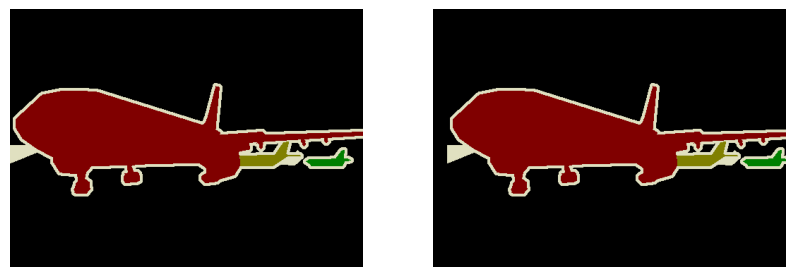

(0.7112011155817279, 1.0)

In [200]:
lbl1 = cv.imread(file2_label)

# shift pixels to the right
shift = 20
lbl2 = np.zeros_like(lbl1)
lbl2[:, shift:, :] = lbl1[:, :-shift, :]

# plot the images
plt.subplots(1, 2, figsize=(10, 5))
plt.subplot(121)
plt.imshow(cv.cvtColor(lbl1, cv.COLOR_BGR2RGB))
plt.axis('off')
plt.subplot(122)
plt.imshow(cv.cvtColor(lbl2, cv.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

dice_score(lbl1, lbl2), dice_score(lbl1, lbl1)